# SqueezeNet 1.1 on EuroSAT RGB

Train and evaluate SqueezeNet using the shared `eurosat_splits.csv` and
`eurosat_classes.json`. This notebook preserves the existing split assignments,
64 x 64 preprocessing, two training stages, and result exports.

Install `requirements.txt`, open this notebook with a Python kernel in the
repository folder, edit the configuration below, and run the cells in order.
The first run downloads ImageNet weights; leaving `data_dir=None` also downloads
the EuroSAT dataset through KaggleHub. Downloads require internet access.
Training uses CUDA when available, otherwise the CPU.

Restart the kernel and run all cells for a fresh experiment. Re-running a training
cell continues with the current in-memory model and history. Outputs are saved
to `output_dir`; choose a new directory to keep previous experiment results.


## Configuration

Set `data_dir` to `Path("C:/datasets/EuroSAT")` if the images are already available;
that directory must contain the ten class folders. Paths below are relative to
the repository folder. Set `ROOT` explicitly if your kernel starts elsewhere.

The defaults train the classifier for 5 epochs and fine-tune for 20. For a shorter
trial, set both epoch counts to 1; this still uses every image in the manifest.
`num_workers=0` supports dataset classes defined in a notebook, including on
Windows. `show_plots=True` displays charts as well as saving them.


In [1]:
from pathlib import Path
from types import SimpleNamespace

ROOT = Path.cwd().resolve()
if not (ROOT / "eurosat_data.py").is_file():
    raise FileNotFoundError("Set ROOT to the repository folder containing eurosat_data.py")

# Keep the shared helper importable if ROOT is set explicitly above.
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

args = SimpleNamespace(
    data_dir=None,  # Or Path("C:/datasets/EuroSAT")
    splits=ROOT / "eurosat_splits.csv",
    classes=ROOT / "eurosat_classes.json",
    output_dir=ROOT / "squeezenet_results",
    seed=42,
    batch_size=64,
    num_workers=0,
    head_epochs=5,
    fine_tune_epochs=20,
    show_plots=True,
)

for name in ("batch_size", "head_epochs", "fine_tune_epochs"):
    value = getattr(args, name)
    if not isinstance(value, int) or isinstance(value, bool) or value < 1:
        raise ValueError(f"{name} must be a positive integer")
if not isinstance(args.num_workers, int) or isinstance(args.num_workers, bool) or args.num_workers < 0:
    raise ValueError("num_workers must be a nonnegative integer")


## Imports and reproducibility

Seed the random generators, select the device, and create the output folder.


In [2]:
import json
import time
import random

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if not args.show_plots:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader

import torchvision
from torchvision import transforms
from torchvision.models import (
    squeezenet1_1,
    SqueezeNet1_1_Weights
)

from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


SEED = args.seed

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_DIR = args.output_dir
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)


C:\Users\User\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu


## Dataset adapter

Open each manifest image as RGB and apply the shared preprocessing.


In [3]:
class EuroSATDataset:
    def __init__(self, manifest, split, root, transform):
        self.frame = (
            manifest[manifest["split"] == split]
            .reset_index(drop=True)
        )
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        from PIL import Image

        row = self.frame.iloc[index]

        with Image.open(
            self.root / row["relative_path"]
        ) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = int(row["label"])
        return image, label


## Load the shared splits and images

Validate the supplied manifest and class order, then check that all images exist.


In [4]:
from eurosat_data import load_splits, validate_images

rows, class_names = load_splits(args.splits, args.classes)
manifest = pd.DataFrame(rows)
NUM_CLASSES = len(class_names)
print(manifest["split"].value_counts())
print("Classes:", class_names)


if args.data_dir is None:
    import kagglehub
    dataset_path = kagglehub.dataset_download("apollo2506/eurosat-dataset")
    DATA_DIR = Path(dataset_path) / "EuroSAT"
else:
    DATA_DIR = args.data_dir

validate_images(rows, DATA_DIR)
print("Dataset directory:", DATA_DIR)
print("All manifest images found.")


split
train    18900
val       4050
test      4050
Name: count, dtype: int64
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Dataset directory: C:\Users\User\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT
All manifest images found.


## Preprocessing and data loaders

Resize to 64 x 64 and normalize with ImageNet statistics, without augmentation. Shuffle only training batches.


In [5]:
IMAGE_SIZE = (64, 64)
BATCH_SIZE = args.batch_size

# Preserve the notebook's preprocessing without augmentation.
image_transform = transforms.Compose([
    transforms.Resize(
        IMAGE_SIZE,
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = EuroSATDataset(
    manifest, "train", DATA_DIR, image_transform
)
val_dataset = EuroSATDataset(
    manifest, "val", DATA_DIR, image_transform
)
test_dataset = EuroSATDataset(
    manifest, "test", DATA_DIR, image_transform
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=args.num_workers,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=args.num_workers,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=args.num_workers,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)


Image batch: torch.Size([64, 3, 64, 64])
Label batch: torch.Size([64])


## Prepare SqueezeNet

Load pretrained weights, freeze the feature extractor, and replace the classifier with one logit per class.


In [6]:
weights = SqueezeNet1_1_Weights.DEFAULT

model = squeezenet1_1(weights=weights)

# Freeze the pretrained feature extractor initially.
for parameter in model.features.parameters():
    parameter.requires_grad = False

# A new classifier produces one logit per EuroSAT class.
# No softmax: CrossEntropyLoss works directly with logits.
model.classifier = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Conv2d(
        in_channels=512,
        out_channels=NUM_CLASSES,
        kernel_size=1
    ),
    nn.AdaptiveAvgPool2d((1, 1))
)

nn.init.normal_(
    model.classifier[1].weight,
    mean=0.0,
    std=0.01
)
nn.init.zeros_(model.classifier[1].bias)

model.num_classes = NUM_CLASSES
model = model.to(device)


def parameter_counts(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable


total, trainable = parameter_counts(model)

print(f"Total parameters: {total:,}")
print(f"Initially trainable parameters: {trainable:,}")

with torch.no_grad():
    output = model(images[:2].to(device))

assert output.shape == (2, NUM_CLASSES)
print("Output shape:", output.shape)


Total parameters: 727,626
Initially trainable parameters: 5,130
Output shape: torch.Size([2, 10])


## Training helpers and checkpoint tracking

Track validation loss across both stages and save the best weights. Run this cell once per fresh experiment; it resets history and checkpoint selection.


In [7]:
criterion = nn.CrossEntropyLoss()

history = []
best_val_loss = float("inf")
BEST_PATH = OUTPUT_DIR / "squeezenet_best_state.pt"


def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in tqdm(
        loader,
        leave=False,
        desc="Train" if training else "Validation"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


def fit_stage(stage_name, epochs, optimizer):
    global best_val_loss

    for _ in range(epochs):
        epoch = len(history) + 1

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        train_loss, train_acc = run_epoch(
            train_loader, optimizer
        )
        val_loss, val_acc = run_epoch(val_loader)

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        history.append({
            "epoch": epoch,
            "stage": stage_name,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_acc,
            "val_accuracy": val_acc,
            "epoch_seconds_including_validation": elapsed
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            # Save weights only, without optimizer state.
            state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            torch.save(state, BEST_PATH)

        pd.DataFrame(history).to_csv(
            OUTPUT_DIR / "training_history.csv",
            index=False
        )

        print(
            f"Epoch {epoch:02d} | {stage_name} | "
            f"train loss={train_loss:.4f}, "
            f"train acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f}, "
            f"val acc={val_acc:.4f} | "
            f"{elapsed:.1f}s"
        )


## Train the classifier

Train only the new classification layer using Adam with a learning rate of 0.001.


In [8]:
head_optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=1e-3
)

fit_stage(
    stage_name="classifier_training",
    epochs=args.head_epochs,
    optimizer=head_optimizer
)


Epoch 01 | classifier_training | train loss=0.4849, train acc=0.8378 | val loss=0.3370, val acc=0.8901 | 151.6s


Epoch 02 | classifier_training | train loss=0.3575, train acc=0.8805 | val loss=0.3311, val acc=0.8904 | 204.5s


Epoch 03 | classifier_training | train loss=0.3522, train acc=0.8837 | val loss=0.3189, val acc=0.8919 | 176.6s


Epoch 04 | classifier_training | train loss=0.3445, train acc=0.8879 | val loss=0.3134, val acc=0.8963 | 159.8s


Epoch 05 | classifier_training | train loss=0.3379, train acc=0.8877 | val loss=0.3253, val acc=0.8948 | 132.6s


## Fine-tune the full model

Reload the best classifier checkpoint, unfreeze the features, and train with lower learning rates. Checkpoint selection continues across both stages.


In [9]:
# Start fine-tuning from the best classifier-stage checkpoint.
model.load_state_dict(
    torch.load(
        BEST_PATH,
        map_location=device,
        weights_only=True
    )
)

for parameter in model.features.parameters():
    parameter.requires_grad = True

fine_tune_optimizer = torch.optim.Adam(
    [
        {
            "params": model.features.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ]
)

total, trainable = parameter_counts(model)

print(f"Total parameters: {total:,}")
print(f"Trainable during fine-tuning: {trainable:,}")

fit_stage(
    stage_name="fine_tuning",
    epochs=args.fine_tune_epochs,
    optimizer=fine_tune_optimizer
)


Total parameters: 727,626
Trainable during fine-tuning: 727,626


Epoch 06 | fine_tuning | train loss=0.2743, train acc=0.9067 | val loss=0.2706, val acc=0.9086 | 204.9s


Epoch 07 | fine_tuning | train loss=0.2341, train acc=0.9210 | val loss=0.2505, val acc=0.9128 | 218.1s


Epoch 08 | fine_tuning | train loss=0.2080, train acc=0.9260 | val loss=0.2335, val acc=0.9153 | 235.8s


Epoch 09 | fine_tuning | train loss=0.1897, train acc=0.9332 | val loss=0.2229, val acc=0.9205 | 209.3s


...

Epoch 21 | fine_tuning | train loss=0.0892, train acc=0.9677 | val loss=0.2018, val acc=0.9356 | 201.6s


Epoch 22 | fine_tuning | train loss=0.0838, train acc=0.9707 | val loss=0.2065, val acc=0.9368 | 202.8s


Epoch 23 | fine_tuning | train loss=0.0773, train acc=0.9718 | val loss=0.2079, val acc=0.9343 | 202.4s


Epoch 24 | fine_tuning | train loss=0.0723, train acc=0.9733 | val loss=0.2001, val acc=0.9360 | 202.8s


Epoch 25 | fine_tuning | train loss=0.0707, train acc=0.9734 | val loss=0.1984, val acc=0.9400 | 201.4s


## Plot training history

Save loss and accuracy curves, marking the transition to fine-tuning.


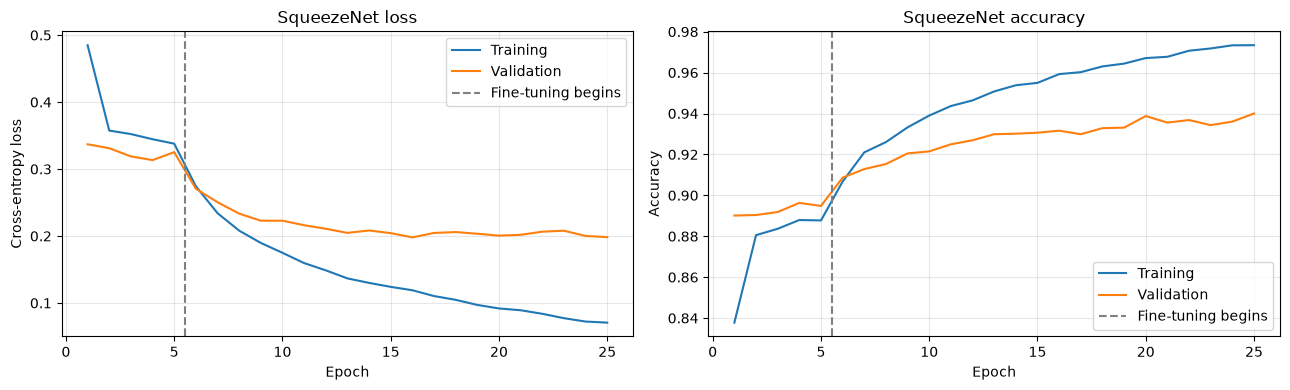

In [10]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
axes[0].set_title("SqueezeNet loss")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation"
)
axes[1].set_title("SqueezeNet accuracy")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.axvline(
        args.head_epochs + 0.5,
        color="gray",
        linestyle="--",
        label="Fine-tuning begins"
    )
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=200,
    bbox_inches="tight"
)
if args.show_plots:
    plt.show()
else:
    plt.close(fig)


## Evaluate the selected checkpoint

Reload the weights with the lowest validation loss and evaluate the held-out test set. Export the classification report and predictions with their image paths.


In [11]:
best_row = history_df.loc[
    history_df["val_loss"].idxmin()
]

print("Selected checkpoint:")
print(best_row[["epoch", "stage", "val_loss", "val_accuracy"]])
model.load_state_dict(
    torch.load(
        BEST_PATH,
        map_location=device,
        weights_only=True
    )
)
model.eval()

y_true = []
y_pred = []
test_loss_sum = 0.0

with torch.no_grad():
    for images, labels in tqdm(
        test_loader,
        desc="Test evaluation"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)
        predictions = logits.argmax(dim=1)

        test_loss_sum += loss.item() * labels.size(0)

        y_true.extend(labels.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

test_accuracy = accuracy_score(y_true, y_pred)
test_loss = test_loss_sum / len(test_dataset)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

pd.DataFrame(report).transpose().to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

# Save predictions with the corresponding image paths.
predictions_df = test_dataset.frame.copy()
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [
    class_names[label] for label in y_pred
]

predictions_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)


Selected checkpoint:
epoch                    16
stage           fine_tuning
val_loss           0.197931
val_accuracy       0.931605
Name: 15, dtype: object


Test evaluation: 100%|██████████| 64/64 [00:26<00:00,  2.42it/s]


Test loss: 0.1787
Test accuracy: 93.90%
                      precision    recall  f1-score   support

          AnnualCrop     0.9156    0.9400    0.9276       450
              Forest     0.9739    0.9933    0.9835       450
HerbaceousVegetation     0.9203    0.9489    0.9344       450
             Highway     0.8833    0.8480    0.8653       375
          Industrial     0.9506    0.9760    0.9632       375
             Pasture     0.9068    0.9400    0.9231       300
       PermanentCrop     0.9467    0.8053    0.8703       375
         Residential     0.9823    0.9844    0.9834       450
               River     0.8966    0.9253    0.9108       375
             SeaLake     0.9912    0.9956    0.9933       450

            accuracy                         0.9390      4050
           macro avg     0.9367    0.9357    0.9355      4050
        weighted avg     0.9391    0.9390    0.9384      4050



## Confusion matrix

Save both a chart and a CSV in the shared class order.


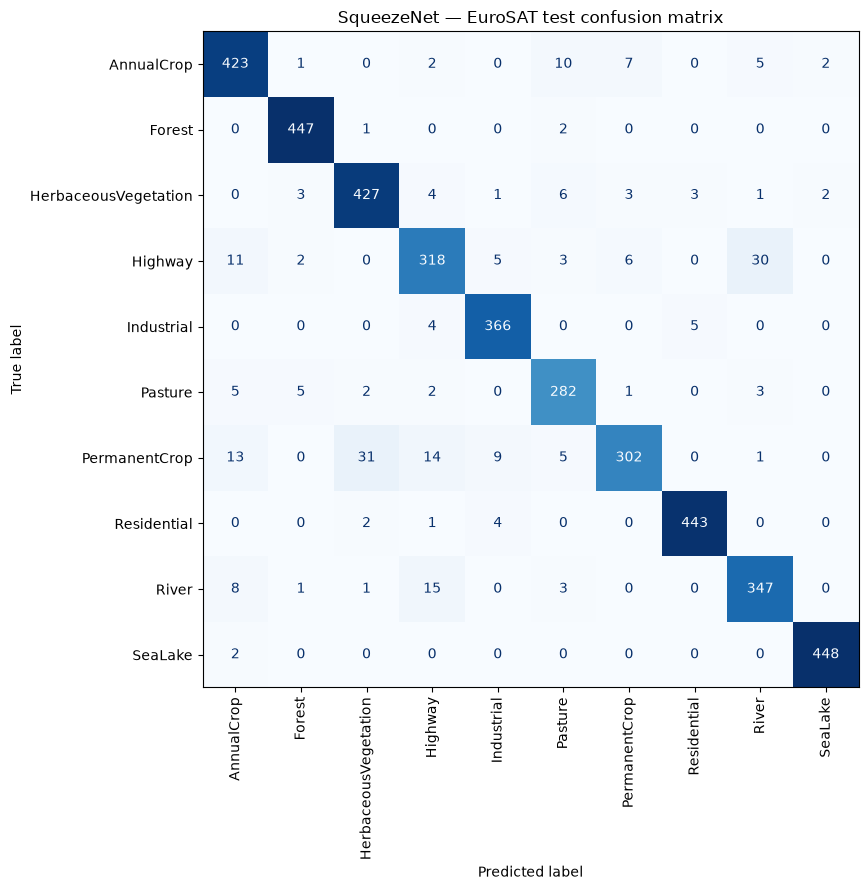

In [12]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(10, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title("SqueezeNet — EuroSAT test confusion matrix")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
if args.show_plots:
    plt.show()
else:
    plt.close(fig)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(OUTPUT_DIR / "confusion_matrix.csv")


## Export model and experiment summaries

Record model size, test metrics, timing, and hashes identifying the shared split files. Save the class names and a copy of the manifest alongside the results.


In [13]:
total_params, trainable_params = parameter_counts(model)

file_bytes = BEST_PATH.stat().st_size

# Decimal MB, explicitly labelled.
model_size_mb = file_bytes / 1_000_000

# Theoretical float32 parameter storage.
fp32_weights_mb = total_params * 4 / 1_000_000

import hashlib

summary = {
    "seed": SEED,
    "split_manifest_sha256": hashlib.sha256(args.splits.read_bytes()).hexdigest(),
    "class_mapping_sha256": hashlib.sha256(args.classes.read_bytes()).hexdigest(),
    "model": "SqueezeNet 1.1",
    "pretrained_weights": str(weights),
    "dataset": "EuroSAT RGB",
    "input_resolution": "64x64",
    "total_parameters": total_params,
    "trainable_parameters_during_fine_tuning": trainable_params,
    "weights_checkpoint_size_MB": model_size_mb,
    "estimated_FP32_parameter_storage_MB": fp32_weights_mb,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "training_epochs": len(history_df),
    "selected_epoch": int(best_row["epoch"]),
    "mean_epoch_seconds_including_validation": float(
        history_df[
            "epoch_seconds_including_validation"
        ].mean()
    )
}



summary_df = pd.DataFrame([summary])
print(summary_df.transpose().to_string(header=False))

summary_df.to_csv(
    OUTPUT_DIR / "model_summary.csv",
    index=False
)

with open(OUTPUT_DIR / "model_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

with open(OUTPUT_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

manifest.to_csv(
    OUTPUT_DIR / "eurosat_splits.csv",
    index=False
)

print(f"Total parameters: {total_params:,}")
print(f"Checkpoint size: {model_size_mb:.3f} MB")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


seed                                                                                                   42
split_manifest_sha256                    af96d32231de08ac8efad7dba66ae543d9a5393be56275a8d5ce3188c2629669
class_mapping_sha256                     1e98de2c33b9ea7ac91a1c1178b2b0529c99e520096fb8a8a414a759937751ce
model                                                                                      SqueezeNet 1.1
pretrained_weights                                                    SqueezeNet1_1_Weights.IMAGENET1K_V1
dataset                                                                                       EuroSAT RGB
input_resolution                                                                                    64x64
total_parameters                                                                                   727626
trainable_parameters_during_fine_tuning                                                            727626
weights_checkpoint_size_MB                    